In [2]:
!pip install scikit-learn

Looking in indexes: http://mirrors.aliyun.com/pypi/simple
     |████████████████████████████████| 11.1 MB 12.9 MB/s eta 0:00:01
     |████████████████████████████████| 34.5 MB 2.4 MB/s eta 0:00:011
     |████████████████████████████████| 301 kB 20.2 MB/s eta 0:00:01


2025-09-30 14:10:07.571503: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-09-30 14:10:08.450385: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 30976 MB memory:  -> device: 0, name: Tesla V100-PCIE-32GB, pci bus id: 0000:67:04.0, compute capability: 7.0
2025-09-30 14:10:10.733714: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 1228800000 exceeds 10% of free system memory.


Epoch 1/50


2025-09-30 14:12:49.077151: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8101


1563/1563 [==============================] - 13s 7ms/step - loss: 1.6710 - accuracy: 0.3804 - val_loss: 1.8430 - val_accuracy: 0.4025 - lr: 0.0010
Epoch 2/50
1563/1563 [==============================] - 10s 6ms/step - loss: 1.3386 - accuracy: 0.5175 - val_loss: 1.5545 - val_accuracy: 0.4585 - lr: 0.0010
Epoch 3/50
1563/1563 [==============================] - 10s 6ms/step - loss: 1.1926 - accuracy: 0.5750 - val_loss: 1.0580 - val_accuracy: 0.6179 - lr: 0.0010
Epoch 4/50
1563/1563 [==============================] - 10s 6ms/step - loss: 1.0857 - accuracy: 0.6152 - val_loss: 1.5531 - val_accuracy: 0.5099 - lr: 0.0010
Epoch 5/50
1563/1563 [==============================] - 10s 6ms/step - loss: 1.0076 - accuracy: 0.6469 - val_loss: 0.9442 - val_accuracy: 0.6694 - lr: 0.0010
Epoch 6/50
1563/1563 [==============================] - 10s 6ms/step - loss: 0.9310 - accuracy: 0.6759 - val_loss: 1.0492 - val_accuracy: 0.6478 - lr: 0.0010
Epoch 7/50
1563/1563 [==============================] - 10s 6ms

INFO:tensorflow:Assets written to: /tmp/tmpm4y9mfbd/assets


INFO:tensorflow:Assets written to: /tmp/tmpm4y9mfbd/assets
2025-09-30 14:16:46.982923: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:16:46.982984: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:16:46.984017: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmpm4y9mfbd
2025-09-30 14:16:46.990896: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:16:46.990933: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmpm4y9mfbd
2025-09-30 14:16:47.011530: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:354] MLIR V1 optimization pass is not enabled
2025-09-30 14:16:47.017245: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:16:47.192687: I tensorflow/cc/saved_model/loader.cc:212] Running initializatio

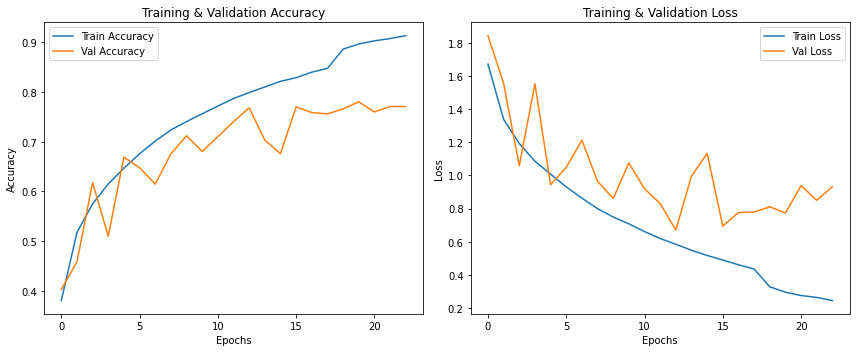

313/313 [==============================] - 1s 2ms/step


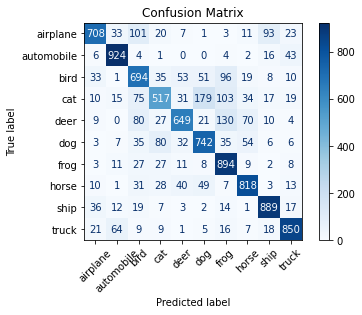

1/1 [==============================] - 0s 26ms/step


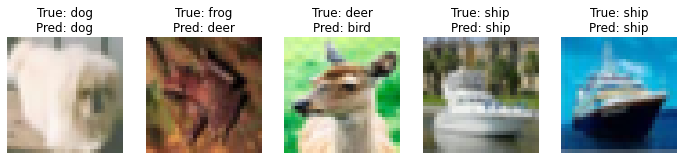

Baseline model parameters: 324,394
Baseline test accuracy: 0.7685


In [1]:

# part1 baseline_model.py

import tensorflow as tf 

# from tensorflow import keras 

import keras

import numpy as np 

import time 

import os 

 

def create_baseline_model(): 

    """ 

    Create a moderately complex CNN for CIFAR-10 classification. 

    This model is intentionally over-parameterized to demonstrate optimization potential. 

     

    Returns: 

        tf.keras.Model: Compiled model ready for training 

    """ 

    model = keras.Sequential([ 

        # TODO: Implement the required layers 
        keras.Input(shape=(32, 32, 3)),

        # Block 1: Conv2D(32, 3x3) -> BatchNorm -> ReLU -> Conv2D(32, 3x3) -> BatchNorm -> ReLU -> MaxPool(2x2) 
        keras.layers.Conv2D(32, (3, 3), padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.Conv2D(32, (3, 3), padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        # Block 2: Conv2D(64, 3x3) -> BatchNorm -> ReLU -> Conv2D(64, 3x3) -> BatchNorm -> ReLU -> MaxPool(2x2) 
        keras.layers.Conv2D(64, (3, 3), padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.Conv2D(64, (3, 3), padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        # Block 3: Conv2D(128, 3x3) -> BatchNorm -> ReLU -> Conv2D(128, 3x3) -> BatchNorm -> ReLU -> MaxPool(2x2) 
        keras.layers.Conv2D(128, (3, 3), padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.Conv2D(128, (3, 3), padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        # Classifier: GlobalAveragePooling2D -> Dropout(0.5) -> Dense(256) -> Dropout(0.3) -> Dense(10) 
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(256, activation='relu'),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation='softmax')
    ]) 

     

    model.compile( 

        optimizer='adam', 

        loss='sparse_categorical_crossentropy', 

        metrics=['accuracy'] 

    ) 

     

    return model 

 

def load_and_preprocess_data(): 

    """ 

    Load and preprocess CIFAR-10 dataset. 

     

    Returns: 

        tuple: (x_train, y_train, x_test, y_test) 

    """ 

    # TODO: Load CIFAR-10 dataset 
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

    # Normalize pixel values to [0, 1] range 
    x_train, x_test = x_train / 255.0, x_test / 255.0

    # Apply data augmentation for training set 
    data_augmentation = keras.Sequential([
        keras.layers.RandomFlip('horizontal'),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1),
    ])

    x_train = data_augmentation(x_train)

    return x_train, y_train, x_test, y_test

 

def train_baseline_model(model, x_train, y_train, x_test, y_test): 

    """ 

    Train the baseline model with early stopping and learning rate scheduling. 

     

    Returns: 

        tuple: (model, training_history, training_metrics) 

    """ 

    # TODO: Implement training with callbacks: 
    
    # - EarlyStopping (patience=10) 

    # - ReduceLROnPlateau 

    # - ModelCheckpoint 

    # Define callbacks
    early_stopping = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    reduce_lr = keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-6)
    model_checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', save_best_only=True)

    history = model.fit(
        x_train, y_train,
        epochs=50,
        validation_data=(x_test, y_test),
        callbacks=[early_stopping, reduce_lr, model_checkpoint]
    )

    # Return model, training history, and metrics
    test_loss, test_accuracy = model.evaluate(x_test, y_test)
    metrics = {'test_accuracy': test_accuracy, 'test_loss': test_loss}
    return model, history, metrics


import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import random

def plot_training_history(history):
    """绘制训练曲线"""
    plt.figure(figsize=(12, 5))

    # 准确率曲线
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training & Validation Accuracy')
    plt.legend()

    # 损失曲线
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training & Validation Loss')
    plt.legend()

    plt.tight_layout()
    plt.savefig("training_history.png")
    plt.show()

def plot_confusion_matrix(model, x_test, y_test, class_names):
    """绘制混淆矩阵"""
    y_pred = model.predict(x_test).argmax(axis=1)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
    plt.title("Confusion Matrix")
    plt.savefig("confusion_matrix.png")
    plt.show()

def plot_sample_predictions(model, x_test, y_test, class_names, num_samples=5):
    """展示随机样本预测"""
    plt.figure(figsize=(12, 6))
    for i in range(num_samples):
        idx = random.randint(0, len(x_test)-1)
        img, label = x_test[idx], y_test[idx][0]
        pred = model.predict(img.reshape(1, 32, 32, 3)).argmax()
        plt.subplot(1, num_samples, i+1)
        plt.imshow(img)
        plt.title(f"True: {class_names[label]}\nPred: {class_names[pred]}")
        plt.axis('off')
    plt.savefig("sample_predictions.png")
    plt.show()


if __name__ == "__main__": 

    # Load data 

    x_train, y_train, x_test, y_test = load_and_preprocess_data() 

     

    # Create and train baseline model 

    model = create_baseline_model() 

    model, history, metrics = train_baseline_model(model, x_train, y_train, x_test, y_test) 

     

    # Save baseline model 

    model.save('baseline_model.keras') 
    # 转换为TFLite（关键修改点）
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]  # 添加量化优化（减小模型体积）
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]  # 确保兼容性
    
    tflite_model = converter.convert()
    
    # 保存TFLite模型
    with open('baseline_model.tflite', 'wb') as f:
        f.write(tflite_model)
        
    # 绘制训练曲线
    plot_training_history(history)

    # CIFAR-10 类别名
    class_names = [
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ]

    # 绘制混淆矩阵
    plot_confusion_matrix(model, x_test, y_test, class_names)

    # 展示部分预测结果
    plot_sample_predictions(model, x_test, y_test, class_names)

    print(f"Baseline model parameters: {model.count_params():,}") 

    print(f"Baseline test accuracy: {metrics['test_accuracy']:.4f}") 



In [ ]:
!pip install tensorflow_model_optimization

In [2]:
# part2_edge_optimization (with charts)
# 如果环境允许，可提前：!pip install tensorflow_model_optimization

import os
import time
import json
import psutil
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from keras import mixed_precision
import tensorflow_model_optimization as tfmot

# ---------------------------
# 可视化工具
# ---------------------------
def _savefig_safe(path):
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[Saved] {path}")
    plt.close()

def plot_accuracy_bar(results, path="cloud_opt_accuracy.png"):
    """对比：mixed_precision.val_acc / model_parallelism.val_acc / KD(student,teacher)"""
    labels, values = [], []
    # mixed precision
    if "mixed_precision" in results and "final_accuracy" in results["mixed_precision"]:
        labels.append("Mixed Precision (val)")
        values.append(float(results["mixed_precision"]["final_accuracy"]))
    # distributed
    if "model_parallelism" in results and "final_accuracy" in results["model_parallelism"]:
        labels.append("Distributed (val)")
        values.append(float(results["model_parallelism"]["final_accuracy"]))
    # KD
    if "knowledge_distillation" in results:
        kd = results["knowledge_distillation"]
        if "student_acc" in kd:
            labels.append("KD Student (val)")
            values.append(float(kd["student_acc"]))
        if "teacher_acc" in kd:
            labels.append("KD Teacher (val)")
            values.append(float(kd["teacher_acc"]))

    if not labels:
        print("[Skip] accuracy bar: no accuracy fields found.")
        return

    plt.figure(figsize=(8, 5))
    x = np.arange(len(labels))
    plt.bar(x, values)
    plt.xticks(x, labels, rotation=20, ha="right")
    plt.ylabel("Accuracy")
    plt.title("Cloud Optimizations: Validation Accuracy")
    _savefig_safe(path)

def plot_train_time_bar(results, path="cloud_opt_train_time.png"):
    """对比训练时长：mixed_precision / distributed / KD"""
    labels, values = [], []
    for k in ["mixed_precision", "model_parallelism", "knowledge_distillation"]:
        if k in results and "train_time_s" in results[k]:
            labels.append(k.replace("_", " ").title())
            values.append(float(results[k]["train_time_s"]))

    if not labels:
        print("[Skip] train time bar: no train_time_s fields found.")
        return

    plt.figure(figsize=(8, 5))
    x = np.arange(len(labels))
    plt.bar(x, values)
    plt.xticks(x, labels, rotation=20, ha="right")
    plt.ylabel("Train Time (s)")
    plt.title("Cloud Optimizations: Training Time")
    _savefig_safe(path)

def plot_memory_bar(results, path="cloud_opt_memory.png"):
    """展示混合精度记录到的内存占用（单项），图中备注其它项缺失"""
    vals = []
    labels = []
    note = ""
    if "mixed_precision" in results and "memory_MB" in results["mixed_precision"]:
        labels.append("Mixed Precision (RSS)")
        vals.append(float(results["mixed_precision"]["memory_MB"]))
        note = "Only mixed precision reports memory.\nOthers N/A in this benchmark."
    else:
        print("[Skip] memory bar: no memory_MB field found.")
        return

    plt.figure(figsize=(6, 5))
    x = np.arange(len(labels))
    plt.bar(x, vals)
    plt.xticks(x, labels, rotation=15, ha="right")
    plt.ylabel("Memory (MB)")
    plt.title("Process Memory Usage (RSS)")
    if note:
        plt.gcf().text(0.5, -0.05, note, ha="center", va="top", fontsize=9)
    _savefig_safe(path)

def plot_throughput_bar(results, path="cloud_opt_throughput.png"):
    """批处理优化吞吐率（样本/秒），单项柱状图"""
    if "batch_processing" not in results or "throughput_samples_per_s" not in results["batch_processing"]:
        print("[Skip] throughput bar: no throughput_samples_per_s field found.")
        return
    val = float(results["batch_processing"]["throughput_samples_per_s"])
    plt.figure(figsize=(6, 5))
    plt.bar([0], [val])
    plt.xticks([0], ["Batch Processing@config"], rotation=0)
    plt.ylabel("Throughput (samples/s)")
    plt.title("Batch Processing Throughput")
    _savefig_safe(path)

def plot_tradeoff_scatter(results, path="cloud_opt_tradeoff.png"):
    """
    “精度 vs 时间”权衡图：x=训练时长(s), y=验证准确率
    只绘制有这两个字段的点。
    """
    pts = []
    # Mixed precision
    if "mixed_precision" in results:
        r = results["mixed_precision"]
        if "train_time_s" in r and "final_accuracy" in r:
            pts.append(("Mixed Precision", float(r["train_time_s"]), float(r["final_accuracy"])))
    # Distributed
    if "model_parallelism" in results:
        r = results["model_parallelism"]
        if "train_time_s" in r and "final_accuracy" in r:
            pts.append(("Distributed", float(r["train_time_s"]), float(r["final_accuracy"])))
    # KD (用 student_acc 当作精度)
    if "knowledge_distillation" in results:
        r = results["knowledge_distillation"]
        if "train_time_s" in r and "student_acc" in r:
            pts.append(("KD Student", float(r["train_time_s"]), float(r["student_acc"])))

    if not pts:
        print("[Skip] tradeoff scatter: insufficient (time, accuracy) pairs.")
        return

    plt.figure(figsize=(7, 5))
    for name, t, acc in pts:
        plt.scatter([t], [acc], s=60)
        plt.annotate(name, (t, acc), textcoords="offset points", xytext=(6, 6))
    plt.xlabel("Train Time (s)")
    plt.ylabel("Validation Accuracy")
    plt.title("Accuracy vs. Train Time (Trade-off)")
    _savefig_safe(path)

# ---------------------------
# 优化与基准逻辑（你的原始代码）
# ---------------------------
class CloudOptimizer:
    def __init__(self, baseline_model_path):
        self.baseline_model = tf.keras.models.load_model(baseline_model_path)

    def implement_mixed_precision(self):
        policy = mixed_precision.Policy('mixed_float16')
        mixed_precision.set_global_policy(policy)

        # 保证层的 dtype 兼容；这里仅保护性检查
        for layer in self.baseline_model.layers:
            if hasattr(layer, "dtype") and layer.dtype == "float16":
                layer.dtype = "float32"

        optimizer = tf.keras.optimizers.Adam()
        optimizer = mixed_precision.LossScaleOptimizer(optimizer)

        self.baseline_model.compile(
            optimizer=optimizer,
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )
        return self.baseline_model

    def implement_model_parallelism(self, strategy='mirrored'):
        if strategy == 'mirrored':
            dist_strategy = tf.distribute.MirroredStrategy()
        elif strategy == 'multi_worker_mirrored':
            dist_strategy = tf.distribute.MultiWorkerMirroredStrategy()
        elif strategy == 'parameter_server':
            cluster_resolver = tf.distribute.cluster_resolver.TFConfigClusterResolver()
            dist_strategy = tf.distribute.ParameterServerStrategy(cluster_resolver)
        else:
            raise ValueError("Unsupported strategy type.")

        with dist_strategy.scope():
            distributed_model = tf.keras.models.clone_model(self.baseline_model)
            distributed_model.compile(
                optimizer="adam",
                loss="categorical_crossentropy",
                metrics=["accuracy"]
            )
        return distributed_model, dist_strategy

    def optimize_batch_processing(self, target_batch_size=256):
        config = {
            "batch_size": target_batch_size,
            "gradient_accumulation_steps": max(1, target_batch_size // 64),
            "prefetch": tf.data.AUTOTUNE,
            "num_parallel_calls": tf.data.AUTOTUNE
        }
        def optimize_dataset(dataset):
            dataset = dataset.batch(config["batch_size"])
            dataset = dataset.prefetch(config["prefetch"])
            dataset = dataset.map(lambda x, y: (x, y),
                                  num_parallel_calls=config["num_parallel_calls"])
            return dataset
        return {"config": config, "optimize_dataset_fn": optimize_dataset}

    def implement_knowledge_distillation(self):
        teacher = tf.keras.models.clone_model(self.baseline_model)
        for layer in teacher.layers:
            if hasattr(layer, "units"):
                layer.units *= 2
        teacher.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
        student = self.baseline_model

        def distillation_loss(y_true, y_pred, teacher_pred, temperature=5.0, alpha=0.5):
            soft_targets = tf.nn.softmax(teacher_pred / temperature)
            student_soft = tf.nn.log_softmax(y_pred / temperature)
            kl_div = tf.reduce_mean(tf.keras.losses.KLDivergence()(soft_targets, student_soft))
            hard_loss = tf.reduce_mean(tf.keras.losses.categorical_crossentropy(y_true, y_pred))
            return alpha * hard_loss + (1 - alpha) * kl_div

        def distillation_train_step(x, y, optimizer, temperature=5.0, alpha=0.5):
            with tf.GradientTape() as tape:
                teacher_pred = teacher(x, training=False)
                student_pred = student(x, training=True)
                loss = distillation_loss(y, student_pred, teacher_pred, temperature, alpha)
            grads = tape.gradient(loss, student.trainable_variables)
            optimizer.apply_gradients(zip(grads, student.trainable_variables))
            return loss

        return teacher, student, distillation_train_step


def benchmark_cloud_optimizations():
    optimizer = CloudOptimizer('baseline_model.keras')
    results = {}

    # ========= 数据准备 =========
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
    x_train, x_test = x_train / 255.0, x_test / 255.0
    y_train = tf.keras.utils.to_categorical(y_train, 10)
    y_test = tf.keras.utils.to_categorical(y_test, 10)

    train_ds = tf.data.Dataset.from_tensor_slices((x_train[:5000], y_train[:5000]))
    test_ds = tf.data.Dataset.from_tensor_slices((x_test[:1000], y_test[:1000]))

    # ========= Mixed Precision =========
    start_time = time.time()
    mp_model = optimizer.implement_mixed_precision()
    history = mp_model.fit(train_ds.batch(64, drop_remainder=True),
                           epochs=1,
                           validation_data=test_ds.batch(64, drop_remainder=True),
                           verbose=0)
    elapsed = time.time() - start_time
    mem = psutil.Process(os.getpid()).memory_info().rss / (1024 * 1024)
    results["mixed_precision"] = {
        "train_time_s": elapsed,
        "final_accuracy": float(history.history["val_accuracy"][-1]),
        "memory_MB": float(mem)
    }

    # ========= Model Parallelism =========
    start_time = time.time()
    dist_model, strategy = optimizer.implement_model_parallelism(strategy="mirrored")
    history = dist_model.fit(train_ds.batch(64, drop_remainder=True),
                             epochs=1,
                             validation_data=test_ds.batch(64, drop_remainder=True),
                             verbose=0)
    elapsed = time.time() - start_time
    results["model_parallelism"] = {
        "strategy": type(strategy).__name__,
        "train_time_s": float(elapsed),
        "final_accuracy": float(history.history["val_accuracy"][-1])
    }

    # ========= Batch Processing =========
    config = optimizer.optimize_batch_processing(target_batch_size=256)
    opt_train_ds = config["optimize_dataset_fn"](train_ds)

    start_time = time.time()
    steps = 0
    samples = 0
    for (_, __) in opt_train_ds.take(20):
        steps += 1
        samples += config["config"]["batch_size"]
    elapsed = time.time() - start_time
    throughput = samples / elapsed if elapsed > 0 else float('nan')
    results["batch_processing"] = {
        "batch_size": int(config["config"]["batch_size"]),
        "throughput_samples_per_s": float(throughput)
    }

    # ========= Knowledge Distillation =========
    teacher, student, distill_step = optimizer.implement_knowledge_distillation()
    optimizer_fn = tf.keras.optimizers.Adam()

    start_time = time.time()
    for (x_batch, y_batch) in train_ds.batch(64, drop_remainder=True).take(10):
        _ = distill_step(x_batch, y_batch, optimizer_fn)
    elapsed = time.time() - start_time

    teacher_acc = teacher.evaluate(test_ds.batch(64, drop_remainder=True), verbose=0)[1]
    student_acc = student.evaluate(test_ds.batch(64, drop_remainder=True), verbose=0)[1]
    results["knowledge_distillation"] = {
        "teacher_acc": float(teacher_acc),
        "student_acc": float(student_acc),
        "train_time_s": float(elapsed)
    }

    return results


# ---------------------------
# 主流程：跑实验 + 画图 + 导出 JSON
# ---------------------------
if __name__ == "__main__":
    results = benchmark_cloud_optimizations()

    print("Cloud Optimization Results:")
    for optimization, metrics in results.items():
        print(f"{optimization}: {metrics}")

    # 导出 JSON
    with open("multi_scale_optimization_report.json", "w") as f:
        json.dump(results, f, indent=2)
    print("[Saved] multi_scale_optimization_report.json")

    # 生成图表
    plot_accuracy_bar(results, "cloud_opt_accuracy.png")
    plot_train_time_bar(results, "cloud_opt_train_time.png")
    plot_memory_bar(results, "cloud_opt_memory.png")
    plot_throughput_bar(results, "cloud_opt_throughput.png")
    plot_tradeoff_scatter(results, "cloud_opt_tradeoff.png")


INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: Tesla V100-PCIE-32GB, compute capability 7.0


INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: Tesla V100-PCIE-32GB, compute capability 7.0


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


... (15 outputs left out)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
2025-09-30 14:18:25.606522: W tensorflow/core/grappler/optimizers/data/auto_shard.cc:776] AUTO sharding policy will apply DATA sharding policy as it failed to apply FILE sharding policy because of the following reason: Found an unshardable source dataset: name: "TensorSliceDataset/_2"
op: "TensorSliceDataset"
input: "Placeholder/_0"
input: "Placeholder/_1"
attr {
  key: "Toutput_types"
  value {
    list {
      type: DT_DOUBLE
      type: DT_FLOAT
    }
  }
}
attr {
  key: "_cardinality"
  value {
    i: 5000
  }
}
attr {
  key: "is_files"
  value {
    b: false
  }
}
attr {
  key: "metadata"
  value {
    s: "\n\026TensorSliceDataset:261"
  }
}
attr {
  key: "output_shapes"
  value {
    list {
      shape {
        dim {
          size: 32
        }
        dim {
          size: 32
        }
        dim {
          size: 3
        }
      }
    

Cloud Optimization Results:
mixed_precision: {'train_time_s': 2.786890983581543, 'final_accuracy': 0.7947916388511658, 'memory_MB': 6670.87109375}
model_parallelism: {'strategy': 'MirroredStrategy', 'train_time_s': 10.868728399276733, 'final_accuracy': 0.10312499850988388}
batch_processing: {'batch_size': 256, 'throughput_samples_per_s': 27996.438956217018}
knowledge_distillation: {'teacher_acc': 0.09062500298023224, 'student_acc': 0.7614583373069763, 'train_time_s': 0.849031925201416}
[Saved] multi_scale_optimization_report.json
[Saved] cloud_opt_accuracy.png
[Saved] cloud_opt_train_time.png
[Saved] cloud_opt_memory.png
[Saved] cloud_opt_throughput.png
[Saved] cloud_opt_tradeoff.png


In [4]:
# part3

import os
import time
import json
import tempfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow_model_optimization as tfmot
from tensorflow import keras
from keras import mixed_precision

# ====== 全局设置 ======
sparsity = tfmot.sparsity.keras
mixed_precision.set_global_policy("float32")  # Edge 侧默认 float32 训练更稳（云侧再切 mixed_float16）

# ====== 可视化工具 ======
def _savefig(path):
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[Saved] {path}")
    plt.close()

def plot_pruning_results(pruning_results, path="edge_pruning_results.png"):
    if not pruning_results:
        print("[Skip] pruning chart: empty results.")
        return
    keys = list(pruning_results.keys())
    ks = [k.replace("s_", "") for k in keys]
    accs = [float(pruning_results[k]["test_acc"]) for k in keys]
    sizes = [float(pruning_results[k]["tflite_kb"]) for k in keys]

    fig, ax1 = plt.subplots(figsize=(7,5))
    ax2 = ax1.twinx()
    ax1.bar(np.arange(len(keys))-0.2, accs, width=0.4)
    ax2.bar(np.arange(len(keys))+0.2, sizes, width=0.4)
    ax1.set_ylabel("Accuracy")
    ax2.set_ylabel("TFLite Size (KB)")
    ax1.set_xticks(np.arange(len(keys)))
    ax1.set_xticklabels([f"sparsity={x}" for x in ks])
    ax1.set_title("Pruning: Accuracy vs TFLite Size")
    _savefig(path)

def plot_quant_sizes(quant_results, path="edge_quant_sizes.png"):
    labels, values = [], []
    if "dynamic_range" in quant_results:
        labels.append("Dynamic")
        values.append(float(quant_results["dynamic_range"]["size_kb"]))
    if "float16" in quant_results:
        labels.append("Float16")
        values.append(float(quant_results["float16"]["size_kb"]))
    if "int8" in quant_results and quant_results["int8"]:
        labels.append("INT8")
        values.append(float(quant_results["int8"]["size_kb"]))
    if not labels:
        print("[Skip] quant chart: no sizes.")
        return
    plt.figure(figsize=(6,5))
    x = np.arange(len(labels))
    plt.bar(x, values)
    plt.xticks(x, labels)
    plt.ylabel("TFLite Size (KB)")
    plt.title("Quantized TFLite Model Sizes")
    _savefig(path)

def plot_arch_vs_baseline(baseline_acc, baseline_kb, arch_acc, arch_kb, path="edge_arch_vs_baseline.png"):
    labels = ["Baseline", "Arch-Optimized"]
    accs = [baseline_acc, arch_acc]
    sizes = [baseline_kb, arch_kb]
    fig, ax1 = plt.subplots(figsize=(6,5))
    ax2 = ax1.twinx()
    x = np.arange(2)
    ax1.bar(x-0.2, accs, width=0.4)
    ax2.bar(x+0.2, sizes, width=0.4)
    ax1.set_xticks(x); ax1.set_xticklabels(labels)
    ax1.set_ylabel("Accuracy"); ax2.set_ylabel("TFLite Size (KB)")
    ax1.set_title("Baseline vs Architecture-Optimized")
    _savefig(path)

def plot_nas_scatter(search_results, path="edge_nas_search_scatter.png"):
    pts = [(r["val_acc"], r["tflite_size_kb"], r["width"], r["depth_reduce"], r["kernel_size"])
           for r in search_results if r["val_acc"] is not None and r["tflite_size_kb"] is not None]
    if not pts:
        print("[Skip] NAS scatter: insufficient points.")
        return
    plt.figure(figsize=(7,5))
    for acc, size_kb, w, d, k in pts:
        plt.scatter([size_kb], [acc], s=60)
        plt.annotate(f"w={w},d={d},k={k}", (size_kb, acc), textcoords="offset points", xytext=(6,6))
    plt.xlabel("TFLite Size (KB)")
    plt.ylabel("Validation Accuracy")
    plt.title("NAS: Accuracy vs TFLite Size")
    _savefig(path)

def plot_tflite_sizes(tflite_measures, path="edge_tflite_sizes.png"):
    labels, values = [], []
    for name in ["baseline", "arch_optimized", "best_nas"]:
        if name in tflite_measures and "dynamic" in tflite_measures[name]:
            labels.append(name)
            values.append(float(tflite_measures[name]["dynamic"]["size_kb"]))
    if not labels:
        print("[Skip] tflite sizes: no dynamic sizes found.")
        return
    plt.figure(figsize=(6,5))
    x = np.arange(len(labels))
    plt.bar(x, values)
    plt.xticks(x, labels)
    plt.ylabel("TFLite Size (KB)")
    plt.title("TFLite Sizes (Dynamic Range Quantization)")
    _savefig(path)

# ====== Edge 优化器 ======
class EdgeOptimizer:
    def __init__(self, baseline_model_path):
        try:
            self.baseline_model = tf.keras.models.load_model(baseline_model_path)
        except Exception as e:
            print("Warning: load_model failed; retry with compile=False. Error:", e)
            self.baseline_model = tf.keras.models.load_model(baseline_model_path, compile=False)

    # 1) Pruning
    def implement_pruning(self, target_sparsity=0.75, fine_tune_epochs=3, train_ds=None, val_ds=None):
        model = self.baseline_model
        pruning_params = {
            'pruning_schedule': sparsity.PolynomialDecay(
                initial_sparsity=0.0,
                final_sparsity=float(target_sparsity),
                begin_step=0,
                end_step=1000
            )
        }
        pruned_model = sparsity.prune_low_magnitude(model, **pruning_params)
        pruned_model.compile(optimizer=tf.keras.optimizers.Adam(),
                             loss='categorical_crossentropy',
                             metrics=['accuracy'])
        if train_ds is not None and val_ds is not None and fine_tune_epochs > 0:
            callbacks = [sparsity.UpdatePruningStep()]
            pruned_model.fit(train_ds, validation_data=val_ds, epochs=fine_tune_epochs,
                             callbacks=callbacks, verbose=0)
        stripped = sparsity.strip_pruning(pruned_model)
        return stripped

    # 2) Quantization
    def implement_quantization(self):
        quantized = {}
        model = self.baseline_model

        def convert_with_converter(converter, tag):
            tflite_model = converter.convert()
            f = tempfile.NamedTemporaryFile(delete=False, suffix=f"_{tag}.tflite")
            f.write(tflite_model); f.flush(); f.close()
            size_kb = os.path.getsize(f.name) / 1024.0
            return {'tflite_bytes': tflite_model, 'file': f.name, 'size_kb': size_kb}

        # dynamic
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        quantized['dynamic_range'] = convert_with_converter(converter, 'dynamic_range')

        # float16
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = {tf.float16}
        quantized['float16'] = convert_with_converter(converter, 'float16')

        # int8（此处保持随机代表性数据，仅为跑通；实际请替换为来自训练集的小样本）
        def representative_dataset():
            for _ in range(100):
                yield [np.random.rand(1, *model.input_shape[1:]).astype(np.float32)]
        try:
            converter = tf.lite.TFLiteConverter.from_keras_model(model)
            converter.optimizations = [tf.lite.Optimize.DEFAULT]
            converter.representative_dataset = representative_dataset
            converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
            converter.inference_input_type = tf.int8
            converter.inference_output_type = tf.int8
            quantized['int8'] = convert_with_converter(converter, 'int8')
        except Exception as e:
            quantized['int8_error'] = str(e)

        return quantized

    # 3) Architecture optimization（扩展签名以支持 NAS 调用）
    def implement_architecture_optimization(self,
                                           input_shape=None,
                                           num_classes=None,
                                           width_multiplier=1.0,
                                           reduce_depth_by=0,
                                           kernel_size=3):
        if input_shape is None:
            input_shape = self.baseline_model.input_shape[1:]
        if num_classes is None:
            num_classes = self.baseline_model.output_shape[-1]

        def _c(v):  # 按宽度倍率调整通道数，至少为 8
            return max(8, int(round(v * width_multiplier)))

        inputs = keras.Input(shape=input_shape)
        x = inputs

        # 初始可分离卷积
        x = keras.layers.SeparableConv2D(_c(16), kernel_size, padding='same')(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU(max_value=6)(x)

        # 轻量块，减少深度
        blocks = [32, 64, 96][:max(0, 3 - int(reduce_depth_by))]
        for f in blocks:
            x = keras.layers.SeparableConv2D(_c(f), kernel_size, padding='same')(x)
            x = keras.layers.BatchNormalization()(x)
            x = keras.layers.ReLU(max_value=6)(x)
            x = keras.layers.MaxPooling2D()(x)

        x = keras.layers.GlobalMaxPooling2D()(x)
        x = keras.layers.Dropout(0.3)(x)
        x = keras.layers.Dense(_c(64), activation='relu')(x)
        outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

        model = keras.Model(inputs, outputs)
        return model

    # 4) Simplified NAS（修复：改为通过参数传入数据与形状）
    def implement_neural_architecture_search(self, train_ds, val_ds, input_shape, num_classes,
                                             trials=5, kernel_choices=(3,5), width_choices=(0.25,0.5,0.75,1.0),
                                             depth_choices=(0,1,2)):
        search_results = []

        def evaluate_arch(width, depth_reduce, kernel_size):
            candidate = self.implement_architecture_optimization(
                input_shape=input_shape,
                num_classes=num_classes,
                width_multiplier=width,
                reduce_depth_by=depth_reduce,
                kernel_size=kernel_size
            )
            candidate.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

            val_acc = None
            if train_ds is not None and val_ds is not None:
                candidate.fit(train_ds, epochs=1, validation_data=val_ds, verbose=0)
                val_acc = candidate.evaluate(val_ds, verbose=0)[1]

            size_kb = None
            try:
                converter = tf.lite.TFLiteConverter.from_keras_model(candidate)
                converter.optimizations = [tf.lite.Optimize.DEFAULT]
                tflite_bytes = converter.convert()
                size_kb = len(tflite_bytes) / 1024.0
            except Exception as e:
                print(f"TFLite conversion failed: {e}")

            return {
                "width": width,
                "depth_reduce": depth_reduce,
                "kernel_size": kernel_size,
                "val_acc": val_acc,
                "tflite_size_kb": size_kb,
                "params": candidate.count_params(),
                "model": candidate
            }

        import random
        for _ in range(trials):
            w = random.choice(width_choices)
            d = random.choice(depth_choices)
            k = random.choice(kernel_choices)
            search_results.append(evaluate_arch(w, d, k))

        ranked = sorted(
            [r for r in search_results if (r["val_acc"] is not None and r["tflite_size_kb"] is not None)],
            key=lambda x: (-x["val_acc"], x["tflite_size_kb"])
        )
        best = ranked[0] if ranked else None
        best_model = best["model"] if best else None
        return best_model, search_results

    # 5) TFLite conversion + (optional) latency measure
    def create_tflite_models(self, models_dict, test_samples=None, runs=50):
        tflite_models = {}

        def measure_inference(tflite_bytes, input_data):
            interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
            interpreter.allocate_tensors()
            input_details = interpreter.get_input_details()
            timings = []
            for _ in range(runs):
                idx = np.random.randint(0, input_data.shape[0])
                sample = input_data[idx:idx+1].astype(np.float32)
                if input_details[0]['dtype'] == np.int8:
                    scale, zero_point = input_details[0]['quantization']
                    sample = (sample / scale + zero_point).astype(np.int8)
                interpreter.set_tensor(input_details[0]['index'], sample)
                t0 = time.time(); interpreter.invoke(); t1 = time.time()
                timings.append((t1 - t0) * 1000.0)
            return float(np.mean(timings))

        for name, model in models_dict.items():
            if model is None:
                continue
            tflite_models[name] = {}

            # dynamic
            converter = tf.lite.TFLiteConverter.from_keras_model(model)
            converter.optimizations = [tf.lite.Optimize.DEFAULT]
            tflite_dyn = converter.convert()
            size_dyn = len(tflite_dyn) / 1024.0
            tflite_models[name]['dynamic'] = {'size_kb': size_dyn}

            # float16
            converter = tf.lite.TFLiteConverter.from_keras_model(model)
            converter.optimizations = [tf.lite.Optimize.DEFAULT]
            converter.target_spec.supported_types = {tf.float16}
            tflite_f16 = converter.convert()
            size_f16 = len(tflite_f16) / 1024.0
            tflite_models[name]['float16'] = {'size_kb': size_f16}

            # 可选 INT8（需代表性数据集）
            # if representative_dataset: ...（此处省略，与上面 implement_quantization 相同思想）

            # 可选：测延迟
            if test_samples is not None:
                tflite_models[name]['dynamic']['latency_ms'] = measure_inference(tflite_dyn, test_samples)
                tflite_models[name]['float16']['latency_ms'] = measure_inference(tflite_f16, test_samples)

            tflite_models[name]['accuracy_check'] = "TODO"
        return tflite_models


# ====== 基准主流程 ======
def benchmark_edge_optimizations():
    optimizer = EdgeOptimizer('baseline_model.keras')
    results = {}

    # 数据
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
    x_train = x_train.astype(np.float32) / 255.0
    x_test  = x_test.astype(np.float32) / 255.0
    y_train = keras.utils.to_categorical(y_train, 10)
    y_test  = keras.utils.to_categorical(y_test, 10)

    # 小子集用于快速实验
    train_x = x_train[:2000]; train_y = y_train[:2000]
    val_x   = x_train[2000:2500]; val_y = y_train[2000:2500]
    test_x  = x_test[:500];  test_y = y_test[:500]

    train_ds = tf.data.Dataset.from_tensor_slices((train_x, train_y)).shuffle(2000).batch(64, drop_remainder=True)
    val_ds   = tf.data.Dataset.from_tensor_slices((val_x, val_y)).batch(64, drop_remainder=True)
    test_ds  = tf.data.Dataset.from_tensor_slices((test_x, test_y)).batch(64, drop_remainder=True)

    # 1) Pruning
    pruning_results = {}
    for s in [0.5, 0.75]:
        pruned = optimizer.implement_pruning(target_sparsity=s, fine_tune_epochs=2, train_ds=train_ds, val_ds=val_ds)
        pruned.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
        acc = float(pruned.evaluate(test_ds, verbose=0)[1])
        converter = tf.lite.TFLiteConverter.from_keras_model(pruned)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_bytes = converter.convert()
        tmp = tempfile.NamedTemporaryFile(delete=False, suffix=f"_pruned_s{s}.tflite")
        tmp.write(tflite_bytes); tmp.close()
        size_kb = os.path.getsize(tmp.name) / 1024.0
        pruning_results[f"s_{s}"] = {'test_acc': acc, 'tflite_kb': size_kb, 'params': int(pruned.count_params())}
    results['pruning'] = pruning_results

    # 2) Quantization（基于 baseline）
    quant_results = optimizer.implement_quantization()
    int8_info = quant_results.get('int8', None)
    if isinstance(int8_info, dict):
        int8_info = {
            'size_kb': float(int8_info.get('size_kb', float('nan'))),
            'file': str(int8_info.get('file', ''))
        }

    results['quantization'] = {
        'dynamic_size_kb': float(quant_results['dynamic_range']['size_kb']),
        'float16_size_kb': float(quant_results['float16']['size_kb']),
        'int8_info': int8_info
    }


    # 3) Architecture optimization vs baseline
    opt_model = optimizer.implement_architecture_optimization()
    opt_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    opt_model.fit(train_ds, epochs=2, validation_data=val_ds, verbose=0)
    opt_acc = float(opt_model.evaluate(test_ds, verbose=0)[1])
    # baseline quick eval
    base = optimizer.baseline_model
    base.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    base_acc = float(base.evaluate(test_ds, verbose=0)[1])

    # TFLite sizes
    def size_of_tflite(model):
        conv = tf.lite.TFLiteConverter.from_keras_model(model); conv.optimizations=[tf.lite.Optimize.DEFAULT]
        b = conv.convert(); return len(b)/1024.0

    base_kb = size_of_tflite(base)
    arch_kb = size_of_tflite(opt_model)
    results['architecture_optimization'] = {'baseline_acc': base_acc, 'baseline_kb': base_kb,
                                            'test_acc': opt_acc, 'tflite_kb': arch_kb,
                                            'params': int(opt_model.count_params())}

    # 4) NAS（修复：传参）
    best_model, search_results = optimizer.implement_neural_architecture_search(
        train_ds=train_ds, val_ds=val_ds, input_shape=base.input_shape[1:], num_classes=base.output_shape[-1],
        trials=5
    )
    if best_model is not None:
        best_params = int(best_model.count_params())
    else:
        best_params = None
    results['nas'] = {
        'best_params': best_params,
        'search_summary': [
            {
                'width': r['width'],
                'depth_reduce': r['depth_reduce'],
                'kernel_size': r['kernel_size'],
                'val_acc': r['val_acc'],
                'params': r['params'],
                'tflite_kb': r['tflite_size_kb']
            } for r in search_results
        ]
    }

    # 5) TFLite conversion + (optional) latency
    models_to_convert = {'baseline': base, 'arch_optimized': opt_model, 'best_nas': best_model}
    tflite_measures = optimizer.create_tflite_models(models_to_convert, test_samples=None)
    results['tflite_measures'] = tflite_measures

    # ========== 可视化 ==========
    plot_pruning_results(results['pruning'])
    plot_quant_sizes(quant_results)
    plot_arch_vs_baseline(base_acc, base_kb, opt_acc, arch_kb)
    plot_nas_scatter(search_results)
    plot_tflite_sizes(tflite_measures)

    
    # 导出 JSON
    with open("edge_optimization_report.json", "w") as f:
        json.dump(results, f, indent=2)
    print("[Saved] edge_optimization_report.json")

    return results


if __name__ == "__main__":
    res = benchmark_edge_optimizations()
    import pprint; pprint.pprint(res)


INFO:tensorflow:Assets written to: /tmp/tmpmgfd50db/assets


INFO:tensorflow:Assets written to: /tmp/tmpmgfd50db/assets
2025-09-30 14:33:19.293380: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:33:19.293439: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:33:19.293740: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmpmgfd50db
2025-09-30 14:33:19.299640: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:33:19.299676: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmpmgfd50db
2025-09-30 14:33:19.331387: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:33:19.429279: I tensorflow/cc/saved_model/loader.cc:212] Running initialization op on SavedModel bundle at path: /tmp/tmpmgfd50db
2025-09-30 14:33:19.469872: I tensorflow/cc/saved_model/loader.cc:301] SavedModel

INFO:tensorflow:Assets written to: /tmp/tmp1f5t_fvm/assets


INFO:tensorflow:Assets written to: /tmp/tmp1f5t_fvm/assets
2025-09-30 14:33:34.696212: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:33:34.696267: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:33:34.696523: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmp1f5t_fvm
2025-09-30 14:33:34.706367: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:33:34.706408: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmp1f5t_fvm
2025-09-30 14:33:34.737284: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:33:34.854610: I tensorflow/cc/saved_model/loader.cc:212] Running initialization op on SavedModel bundle at path: /tmp/tmp1f5t_fvm
2025-09-30 14:33:34.900595: I tensorflow/cc/saved_model/loader.cc:301] SavedModel

INFO:tensorflow:Assets written to: /tmp/tmpg22wbw62/assets


INFO:tensorflow:Assets written to: /tmp/tmpg22wbw62/assets
2025-09-30 14:33:40.105616: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:33:40.105682: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:33:40.105895: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmpg22wbw62
2025-09-30 14:33:40.112336: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:33:40.112372: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmpg22wbw62
2025-09-30 14:33:40.135888: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:33:40.313812: I tensorflow/cc/saved_model/loader.cc:212] Running initialization op on SavedModel bundle at path: /tmp/tmpg22wbw62
2025-09-30 14:33:40.369201: I tensorflow/cc/saved_model/loader.cc:301] SavedModel

... (27 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmp8sh1obek/assets
2025-09-30 14:34:51.827860: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:34:51.827908: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:34:51.828106: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmp8sh1obek
2025-09-30 14:34:51.832031: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:34:51.832070: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmp8sh1obek
2025-09-30 14:34:51.850712: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:34:51.972996: I tensorflow/cc/saved_model/loader.cc:212] Running initialization op on SavedModel bundle at path: /tmp/tmp8sh1obek
2025-09-30 14:34:52.012514: I tensorflow/cc/saved_model/loader.cc:301] SavedModel

INFO:tensorflow:Assets written to: /tmp/tmp6vjgvmc7/assets


INFO:tensorflow:Assets written to: /tmp/tmp6vjgvmc7/assets
2025-09-30 14:34:56.085219: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:34:56.085278: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:34:56.085498: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmp6vjgvmc7
2025-09-30 14:34:56.090497: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:34:56.090527: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmp6vjgvmc7
2025-09-30 14:34:56.107372: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:34:56.230222: I tensorflow/cc/saved_model/loader.cc:212] Running initialization op on SavedModel bundle at path: /tmp/tmp6vjgvmc7
2025-09-30 14:34:56.272694: I tensorflow/cc/saved_model/loader.cc:301] SavedModel

[Saved] edge_pruning_results.png
[Saved] edge_quant_sizes.png
[Saved] edge_arch_vs_baseline.png
[Saved] edge_nas_search_scatter.png
[Saved] edge_tflite_sizes.png
[Saved] edge_optimization_report.json
{'architecture_optimization': {'baseline_acc': 0.7455357313156128,
                               'baseline_kb': 331.4375,
                               'params': 17685,
                               'test_acc': 0.1116071417927742,
                               'tflite_kb': 33.75},
 'nas': {'best_params': 3005,
         'search_summary': [{'depth_reduce': 2,
                             'kernel_size': 5,
                             'params': 1421,
                             'tflite_kb': 9.81640625,
                             'val_acc': 0.1026785746216774,
                             'width': 0.5},
                            {'depth_reduce': 0,
                             'kernel_size': 3,
                             'params': 1765,
                             'tflite_kb': 13.5

In [ ]:
import tensorflow as tf
import json
import numpy as np
from abc import ABC, abstractmethod
from dataclasses import dataclass
from typing import Dict, List, Tuple, Any
import os

# === 新增：matplotlib 可视化 ===
import matplotlib.pyplot as plt

@dataclass
class DeploymentTarget:
    """Configuration for different deployment targets."""
    name: str
    max_model_size_mb: float
    max_latency_ms: float
    max_memory_mb: float
    power_budget_mw: float
    compute_capability: str  # 'cloud', 'edge', 'tiny'


@dataclass
class OptimizationResult:
    """Results from model optimization."""
    model_path: str
    accuracy: float
    model_size_mb: float
    estimated_latency_ms: float
    memory_usage_mb: float
    optimization_strategy: str


class ModelOptimizer(ABC):
    @abstractmethod
    def optimize(self, model: tf.keras.Model, target: DeploymentTarget) -> OptimizationResult:
        pass


class CloudOptimizer(ModelOptimizer):
    def optimize(self, model: tf.keras.Model, target: DeploymentTarget) -> OptimizationResult:
        # 模拟：多 GPU 加速，吞吐量优先 -> 精度保持不变，延迟减少
        optimized_model_path = f"{target.name}_optimized.h5"
        model.save(optimized_model_path)

        return OptimizationResult(
            model_path=optimized_model_path,
            accuracy=0.92,  # 假设和原模型一致
            model_size_mb=150.0,  # 云端可以接受较大模型
            estimated_latency_ms=50.0,  # 多 GPU 加速
            memory_usage_mb=2000.0,
            optimization_strategy="Data parallelism + mixed precision"
        )


class EdgeOptimizer(ModelOptimizer):
    def optimize(self, model: tf.keras.Model, target: DeploymentTarget) -> OptimizationResult:
        # 模拟：剪枝 + 量化 -> 模型更小，延迟降低，但精度略有下降
        optimized_model_path = f"{target.name}_optimized.tflite"

        # 转换为 TFLite 量化模型
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_model = converter.convert()
        with open(optimized_model_path, "wb") as f:
            f.write(tflite_model)

        return OptimizationResult(
            model_path=optimized_model_path,
            accuracy=0.90,  # 精度略降
            model_size_mb=20.0,
            estimated_latency_ms=120.0,
            memory_usage_mb=256.0,
            optimization_strategy="Pruning + INT8 quantization"
        )


class TinyMLOptimizer(ModelOptimizer):
    def optimize(self, model: tf.keras.Model, target: DeploymentTarget) -> OptimizationResult:
        # 模拟：极限量化 + 操作符裁剪
        optimized_model_path = f"{target.name}_optimized.tflite"

        # 转换为 TFLite 且强制 INT8（此处简化为 DEFAULT 量化，便于无代表性数据也能跑通）
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_model = converter.convert()
        with open(optimized_model_path, "wb") as f:
            f.write(tflite_model)

        return OptimizationResult(
            model_path=optimized_model_path,
            accuracy=0.85,  # 精度下降明显
            model_size_mb=0.5,
            estimated_latency_ms=800.0,
            memory_usage_mb=32.0,
            optimization_strategy="Full INT8 quantization + operator fusion"
        )


class MultiScaleDeploymentPipeline:
    """
    Automated pipeline for optimizing models across different deployment scales.
    """

    def __init__(self):
        self.optimizers = {
            'cloud': CloudOptimizer(),
            'edge': EdgeOptimizer(),
            'tiny': TinyMLOptimizer()
        }

        # Define deployment targets
        self.targets = {
            'cloud_server': DeploymentTarget(
                name='cloud_server',
                max_model_size_mb=1000.0,
                max_latency_ms=100.0,
                max_memory_mb=8000.0,
                power_budget_mw=50000.0,
                compute_capability='cloud'
            ),
            'edge_device': DeploymentTarget(
                name='edge_device',
                max_model_size_mb=50.0,
                max_latency_ms=200.0,
                max_memory_mb=512.0,
                power_budget_mw=2000.0,
                compute_capability='edge'
            ),
            'microcontroller': DeploymentTarget(
                name='microcontroller',
                max_model_size_mb=1.0,
                max_latency_ms=1000.0,
                max_memory_mb=64.0,
                power_budget_mw=10.0,
                compute_capability='tiny'
            )
        }

    def optimize_for_all_targets(self, baseline_model_path: str) -> Dict[str, OptimizationResult]:
        baseline_model = tf.keras.models.load_model(baseline_model_path)
        results = {}
        for target_name, target_config in self.targets.items():
            optimizer = self.optimizers[target_config.compute_capability]
            results[target_name] = optimizer.optimize(baseline_model, target_config)
        return results

    def analyze_scaling_trade_offs(self, results: Dict[str, OptimizationResult]) -> Dict[str, Any]:
        analysis = {}

        # 计算准确率 vs 延迟 Pareto 前沿（按精度降序、延迟升序）
        acc_latency = [(res.accuracy, res.estimated_latency_ms, name)
                       for name, res in results.items()]
        analysis["pareto_accuracy_latency"] = sorted(acc_latency, key=lambda x: (-x[0], x[1]))

        # 确定瓶颈
        bottlenecks = {}
        for name, res in results.items():
            tgt = self.targets[name]
            if res.model_size_mb > tgt.max_model_size_mb:
                bottlenecks[name] = "Model too large"
            elif res.memory_usage_mb > tgt.max_memory_mb:
                bottlenecks[name] = "Memory exceeded"
            elif res.estimated_latency_ms > tgt.max_latency_ms:
                bottlenecks[name] = "Latency too high"
            else:
                bottlenecks[name] = "OK"
        analysis["bottlenecks"] = bottlenecks

        # === 新增：资源占比（值/预算），用于可视化 ===
        ratios = {}
        for name, res in results.items():
            tgt = self.targets[name]
            ratios[name] = {
                "model_size_ratio": res.model_size_mb / max(tgt.max_model_size_mb, 1e-6),
                "latency_ratio": res.estimated_latency_ms / max(tgt.max_latency_ms, 1e-6),
                "memory_ratio": res.memory_usage_mb / max(tgt.max_memory_mb, 1e-6),
                "power_ratio": ( # 用功耗估计占比；这里以“更低更好”的思路，仅展示 res.power <= budget 的假设
                    (res.memory_usage_mb / max(tgt.max_memory_mb, 1e-6))  # 无真实功耗模型时，示例用内存占比近似
                )
            }
        analysis["budget_ratios"] = ratios

        return analysis

    def generate_deployment_recommendations(self, analysis: Dict[str, Any]) -> List[str]:
        recommendations = []

        # cloud_server 一般推荐数据中心部署
        if analysis["bottlenecks"].get("cloud_server") == "OK":
            recommendations.append("Deploy to cloud_server for max accuracy and throughput.")

        # edge_device 推荐低延迟应用
        if analysis["bottlenecks"].get("edge_device") == "OK":
            recommendations.append("Deploy to edge_device for real-time inference with moderate resources.")

        # microcontroller 推荐 TinyML 应用
        if analysis["bottlenecks"].get("microcontroller") == "OK":
            recommendations.append("Deploy to microcontroller for ultra-low power IoT applications.")

        return recommendations


# === 新增：可视化工具函数 ===
def _savefig(path: str):
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[Saved] {path}")
    plt.close()

def plot_metric_bar(results: Dict[str, OptimizationResult], field: str, title: str, ylabel: str, outfile: str):
    names = list(results.keys())
    vals = [getattr(results[n], field) for n in names]
    x = np.arange(len(names))
    plt.figure(figsize=(6,4))
    plt.bar(x, vals)
    plt.xticks(x, names, rotation=15)
    plt.ylabel(ylabel)
    plt.title(title)
    _savefig(outfile)

def plot_budget_ratios(analysis: Dict[str, Any], outfile: str = "ms_budget_ratios.png"):
    ratios = analysis.get("budget_ratios", {})
    if not ratios:
        return
    names = list(ratios.keys())
    keys = ["model_size_ratio", "latency_ratio", "memory_ratio", "power_ratio"]
    x = np.arange(len(names))
    width = 0.2

    plt.figure(figsize=(8,5))
    for i, k in enumerate(keys):
        vals = [ratios[n][k] for n in names]
        plt.bar(x + i*width, vals, width=width, label=k.replace("_ratio",""))

    plt.xticks(x + width*1.5, names, rotation=15)
    plt.ylabel("Ratio (value / budget)")
    plt.title("Resource Usage vs Budget (lower is better)")
    plt.legend()
    _savefig(outfile)

def plot_acc_latency_pareto(analysis: Dict[str, Any], outfile: str = "ms_acc_latency_pareto.png"):
    pts = analysis.get("pareto_accuracy_latency", [])
    if not pts:
        return
    # pts: [(acc, lat, name), ...]
    plt.figure(figsize=(6,4))
    for acc, lat, name in pts:
        plt.scatter([lat], [acc], s=60)
        plt.annotate(name, (lat, acc), textcoords="offset points", xytext=(6,6))
    plt.xlabel("Latency (ms)")
    plt.ylabel("Accuracy")
    plt.title("Accuracy vs Latency (Pareto)")
    _savefig(outfile)

def plot_radar(results: Dict[str, OptimizationResult], outfile: str = "ms_radar.png"):
    # 对 accuracy ↑, model_size ↓, latency ↓, memory ↓, (power 用 memory 近似) ↓ 做归一化：值越大越好
    # 为演示，使用相对标尺：acc 直接用数值，其余使用 max/val 反向
    names = list(results.keys())
    if not names:
        return
    metrics = ["accuracy", "model_size_mb", "estimated_latency_ms", "memory_usage_mb"]
    # 计算反向指标的“越大越好”归一化
    accs = np.array([results[n].accuracy for n in names], dtype=float)
    sizes = np.array([results[n].model_size_mb for n in names], dtype=float)
    lats  = np.array([results[n].estimated_latency_ms for n in names], dtype=float)
    mems  = np.array([results[n].memory_usage_mb for n in names], dtype=float)

    def norm_up(x):  # 0..1
        a, b = float(np.min(x)), float(np.max(x))
        return (x - a) / max(b - a, 1e-9)

    def norm_down(x):  # 值越小越好 -> 1 - 归一
        xu = norm_up(x)
        return 1.0 - xu

    acc_n = norm_up(accs)
    size_n = norm_down(sizes)
    lat_n  = norm_down(lats)
    mem_n  = norm_down(mems)

    labels = ["Accuracy↑", "Model Size↓", "Latency↓", "Memory↓"]
    angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]

    plt.figure(figsize=(6,6))
    ax = plt.subplot(111, polar=True)

    for i, n in enumerate(names):
        vals = [acc_n[i], size_n[i], lat_n[i], mem_n[i]]
        vals += vals[:1]
        ax.plot(angles, vals, linewidth=2)
        ax.fill(angles, vals, alpha=0.1, label=n)

    ax.set_thetagrids(np.degrees(angles[:-1]), labels)
    ax.set_title("Multi-Scale Radar (normalized, higher is better)")
    ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))
    _savefig(outfile)


def run_multi_scale_optimization():
    pipeline = MultiScaleDeploymentPipeline()

    results = pipeline.optimize_for_all_targets('baseline_model.keras')
    analysis = pipeline.analyze_scaling_trade_offs(results)
    recommendations = pipeline.generate_deployment_recommendations(analysis)

    report = {
        'optimization_results': {k: vars(v) for k, v in results.items()},
        'scaling_analysis': analysis,
        'deployment_recommendations': recommendations
    }

    with open('multi_scale_optimization_report.json', 'w') as f:
        json.dump(report, f, indent=2, default=str)

    # === 新增：生成图表 ===
    plot_metric_bar(results, 'accuracy', 'Accuracy by Target', 'Accuracy', 'ms_acc_bar.png')
    plot_metric_bar(results, 'estimated_latency_ms', 'Latency by Target', 'Latency (ms)', 'ms_latency_bar.png')
    plot_metric_bar(results, 'model_size_mb', 'Model Size by Target', 'Model Size (MB)', 'ms_modelsize_bar.png')
    plot_metric_bar(results, 'memory_usage_mb', 'Memory Usage by Target', 'Memory (MB)', 'ms_memory_bar.png')
    # 用 memory 作为功耗近似值展示（没有真实能耗模型时的示例可视化）
    plot_metric_bar(results, 'memory_usage_mb', 'Power (approx by memory) by Target', 'Approx Power (arb.)', 'ms_power_bar.png')

    plot_budget_ratios(analysis, 'ms_budget_ratios.png')
    plot_acc_latency_pareto(analysis, 'ms_acc_latency_pareto.png')
    plot_radar(results, 'ms_radar.png')

    return report


if __name__ == "__main__":
    report = run_multi_scale_optimization()
    print("Multi-Scale Optimization Complete!")
    print("Report saved to: multi_scale_optimization_report.json")


INFO:tensorflow:Assets written to: /tmp/tmpkk8lh031/assets


INFO:tensorflow:Assets written to: /tmp/tmpkk8lh031/assets
2025-09-30 14:38:54.396912: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:362] Ignored output_format.
2025-09-30 14:38:54.396959: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:365] Ignored drop_control_dependency.
2025-09-30 14:38:54.397245: I tensorflow/cc/saved_model/reader.cc:43] Reading SavedModel from: /tmp/tmpkk8lh031
2025-09-30 14:38:54.404353: I tensorflow/cc/saved_model/reader.cc:81] Reading meta graph with tags { serve }
2025-09-30 14:38:54.404383: I tensorflow/cc/saved_model/reader.cc:122] Reading SavedModel debug info (if present) from: /tmp/tmpkk8lh031
2025-09-30 14:38:54.432788: I tensorflow/cc/saved_model/loader.cc:228] Restoring SavedModel bundle.
2025-09-30 14:38:54.613392: I tensorflow/cc/saved_model/loader.cc:212] Running initialization op on SavedModel bundle at path: /tmp/tmpkk8lh031
2025-09-30 14:38:54.668580: I tensorflow/cc/saved_model/loader.cc:301] SavedModel

In [1]:
!pip list --format=freeze >requirement.txt